# Purpose
## The primary task is to find correlations between the price of a vehcile and other attributes, such as year, make, etc. 

## The secondary task is to explore any correlation that exists between other attributes. 

# There are some preliminary preparation tasks you should complete before the EDA tasks.

### a.	Adequacy Check: Make sure that the dataset is large enough and representative of the problem you're trying to solve. Ensure it includes relevant variables for the analysis you're aiming to perform. 

The datasets contain over 9000 rows of data, more than enough to establish findings. However, if we want to predict the price of a Tesla Model Y or a Ford F-150, we only have a dozen or so rows for those specific makes/models. We will proceed with the EDA, but adjust our goals based on appropriate size of data. For example, we might target a Hyundai Palisade if this make/model contains a larger dataset than other makes/models.

### b.	Data Integrity: Check for source information and understand its data collection methodology and if there are any potential biases in the dataset. Sometimes datasets come with unclear or misleading variable names, so it’s essential to interpret them in context. 

The data comes from https://www.kaggle.com/datasets/ahmedgmy/cars-raw-dataset

Kaggle is a common dataset sharing website and while I do not know the author Ahmed Gamal personally, I verified the data by searching the VINs of cars within the dataset on CARFAX. CARFAX verified several makes/models of different cars when I searched the VINs, verifiying the authenticity of the dataset. 

There are various scores to reliability, dealer seller rating, etc. While these could be skewed or bias, we will press forward with our analysis. However the data seems to be consistent with normal Google/seller reviews. For example, BG Motorcars in IL had a Seller Rating of 4.1 and on Google, it had 3.9 out of 5 stars. 

In [3]:
!pip install prettytable

In [4]:
import pandas as pd
from prettytable import PrettyTable

# Load the data
cars_df = pd.read_csv("cars_raw.csv")



# 2.	Data Cleaning and Preparation 

##    a.	Handle missing values or outliers  

In [5]:

# Drop rows where Price is "Not Priced"
cars_df = cars_df[cars_df['Price'] != 'Not Priced']


# We have to change price to number
# Drop dollar sign
cars_df['Price'] = cars_df['Price'].str.replace('$', '', regex=False)

# Drop comma
cars_df['Price'] = cars_df['Price'].str.replace(',', '', regex=False)

# Convert to int
cars_df['Price'] = cars_df['Price'].astype(int)


# Count of missing values per column
missing_sum = cars_df.isnull().sum()

# Percentage of missing values per column
missing_mean = cars_df.isnull().mean()

# Rows with any missing values
missing_rows = cars_df[cars_df.isnull().any(axis=1)]

# Print summary
print(f"Total missing values in DataFrame: {missing_sum.sum()}")
print(f"Average missing percentage per column: {missing_mean.mean():.2%}")
# While we could use some imputation for things such as missing miles, or price, that would require us to find associated make/models of the same year, and dropping the frames is easier.
cleaned_cars_df = cars_df.dropna()

# Make a new column called year, to add a numerical col instead of a categorical one.
cleaned_cars_df['Age'] = 2025 - cleaned_cars_df['Year']
cleaned_cars_df.drop(columns=['Year'], inplace=True)



Total missing values in DataFrame: 222
Average missing percentage per column: 0.07%


C:\Users\Gabe\AppData\Local\Temp\ipykernel_76712\400087713.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_cars_df['Age'] = 2025 - cleaned_cars_df['Year']
C:\Users\Gabe\AppData\Local\Temp\ipykernel_76712\400087713.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_cars_df.drop(columns=['Year'], inplace=True)


## b. Recoding or encoding of variables   

## c. Data transformation if certain variables are skewed or have extreme values  

## d. Normalization or Standardization (Note. If you're going to apply machine learning algorithms (e.g., clustering, classification), it’s critical to know if normalization or standardization is applied to your variables)   

In [6]:
#! Note! We will standardize and encode AFTER separating by make/model, as the make model will have their own distributions and we want to keep that information intact.
#! However, we can write the functions NOW, so we can use them later.


def encode_categorical(df, columns):
    for column in columns:
        df[column] = df[column].astype('category').cat.codes
    return df

def standardize_numerical(df, columns):
    for column in columns:
        mean = df[column].mean()
        std = df[column].std()
        df[column] = (df[column] - mean) / std
    return df

# For models comparing against each other, we will drop constant columns, such as "comfort rating". This is easier just to keep only the columns we want.
unique_col = "Model"
numerical_columns = ["ConsumerRating", "ConsumerReviews", "SellerRating", "SellerReviews", "Mileage","Age"]
target = "Price"
# State and zipcode might be redundant, but we will keep them for now.
categorical_columns = ['SellerName', 'State', 'DealType','Zipcode']

relevant_columns = numerical_columns + categorical_columns + [target] + [unique_col]

cleaned_cars_df = cleaned_cars_df[relevant_columns]
cleaned_cars_df


,ConsumerRating,ConsumerReviews,SellerRating,SellerReviews,Mileage,Age,SellerName,State,DealType,Zipcode,Price,Model
0,4.6,45,3.3,3,29403,6,CarMax Murrieta - Now offering Curbside Pickup...,CA,Great,92562,39998,Sienna SE
1,4.8,817,4.8,131,32929,7,Giant Chevrolet,CA,Good,93292,49985,F-150 Lariat
2,4.7,495,4.6,249,23173,8,Gill Auto Group Madera,CA,Good,93637,41860,1500 Laramie
4,4.8,76,4.8,4755,28137,5,Lexus of Henderson,NV,Good,89011,49000,RX 350
5,4.7,34,4.4,1071,105469,13,AutoNation Toyota Hayward,CA,Fair,94544,23541,4Runner SR5
...,...,...,...,...,...,...,...,...,...,...,...,...
9374,4.7,205,4.4,443,15606,6,Bertera Subaru of West Springfield,MA,Good,01089,27374,Crosstrek 2.0i Premium
9375,4.8,27,4.8,1789,46855,6,Autobahn USA Westborough,MA,Fair,01581,61998,Q8 3.0T Premium
9376,4.8,137,4.7,831,62649,8,Tulley Automotive Group,NH,Good,03060,26944,Enclave Leather
9377,4.7,279,4.4,680,30760,6,Ira Subaru,MA,Good,01923,28568,Forester Premium


In [7]:
# Count unique values and sort by frequency (descending)
mode_counts = cleaned_cars_df['Model'].value_counts()

# Print the top 20 models by count
print("Top 20 unique values in 'Model' sorted by count:")
print(mode_counts.head(20))


'''
The most popular models for sale are Grand Cherokee Limited, CR-V, and X5. 
When we compare models, we have to be cognizant of variances between generations.

For example, the Grand Cherokee is fairly easy because it's the same car/trim across several rows.
At a glance, we assume the X5 is probably the same as other X5s, but the xDrive40i and xDrive35i are different generations,
leading to variances in pricing and reliability. 

Further analysis might compare models against models, but we should also save off the top 3 models against themselves for model-specific analysis
'''

grand_cherokee_df = cleaned_cars_df[cleaned_cars_df['Model'] == "Grand Cherokee Limited"]
crv_df = cleaned_cars_df[cleaned_cars_df['Model'] == "CR-V EX-L"]
x5_drive40i = cleaned_cars_df[cleaned_cars_df['Model'] == "X5 xDrive40i"]

top_3_cars_df= [grand_cherokee_df,crv_df,x5_drive40i]

Top 20 unique values in 'Model' sorted by count:
Model
Grand Cherokee Limited    265
CR-V EX-L                 189
X5 xDrive40i              164
XT5 Luxury                140
RAV4 LE                   112
GX 460 Base               111
X3 xDrive30i              108
Pilot EX-L                102
CX-5 Grand Touring         99
1500 Laramie               87
C-Class C 300              83
Corolla LE                 79
CR-V EX                    77
QX60 Luxe                  75
GLC 300 Base 4MATIC        72
RX 350 Base                72
RAV4 XLE                   71
4Runner Limited            69
C-Class C 300 4MATIC       65
330 i xDrive               64
Name: count, dtype: int64


In [8]:
grand_cherokee_df

,ConsumerRating,ConsumerReviews,SellerRating,SellerReviews,Mileage,Age,SellerName,State,DealType,Zipcode,Price,Model
243,4.8,224,4.7,4644,32858,6,Scott Clark Toyota,NC,Great,28105,35500,Grand Cherokee Limited
276,4.8,334,4.3,1366,16929,8,Bill Luke Chrysler Jeep Dodge RAM,AZ,Great,85015,27575,Grand Cherokee Limited
300,4.8,224,4.5,1343,33995,6,Mercedes-Benz of Houston North,TX,Good,77090,34991,Grand Cherokee Limited
372,4.8,224,3.0,2,39412,6,EchoPark Automotive Salt Lake City Delivery Ce...,UT,Good,84115,39439,Grand Cherokee Limited
400,4.8,395,4.3,17,43807,7,Brickner's of Antigo Inc.,WI,Great,54409,33663,Grand Cherokee Limited
...,...,...,...,...,...,...,...,...,...,...,...,...
9133,4.8,395,4.4,228,30923,7,Walser Subaru,MN,Great,55306,33998,Grand Cherokee Limited
9224,4.8,224,4.8,1295,60434,6,"Napleton Hyundai, Genesis of Hazelwood",MO,Great,63042,29900,Grand Cherokee Limited
9261,4.8,395,4.8,558,33639,7,Susquehanna Chrysler Dodge Jeep RAM,PA,Good,17368,32990,Grand Cherokee Limited
9269,4.8,224,4.6,228,42579,6,Hertrich Chrysler Dodge Jeep Ram of Elkton,MD,Fair,21921,40971,Grand Cherokee Limited


1.	Describe the Variable Characteristics with Summary Statistics  
a.	Provide description of the variables you are using in this project.  


In [9]:
from prettytable import PrettyTable
import pandas as pd

# Sample DataFrame (replace this with your actual df)
# cars_df = pd.read_csv("your_data.csv")  # Example

# Notes dictionary
notes_dict = {
    'Price': 'Target variable we want to predict',
    'DealType': 'Based on MSRP/KBB Value of car vs price',
    'ConsumerRating': 'Average consumer rating of the car',
    'ConsumerReviews': 'Number of consumer reviews for the car',
    'SellerRating': 'Average seller rating of the car',
    'SellerReviews': 'Number of seller reviews for the car',
    'Mileage': 'Mileage of the car in miles',
    'State': 'State where the car is being sold',
    'Zipcode': 'Zipcode where the car is being sold',
    'SellerName': 'Name of the seller, encoded as a category',
    'Age': 'Age of the car in years, calculated from the current year minus the year of manufacture'
}

# Create the PrettyTable
table = PrettyTable()
table.field_names = ["Column Name", "Data Type", "Example Data", "Notes"]

# Helper function to classify type
def classify_type(series):
    if pd.api.types.is_numeric_dtype(series):
        return "Numerical"
    elif series.nunique(dropna=True) == 2:
        return "Binary"
    else:
        return "Categorical"

# Fill the table
for col in grand_cherokee_df.columns:
    col_name = col
    data_type = classify_type(grand_cherokee_df[col])
    example_data = str(grand_cherokee_df[col].iloc[0])
    note = notes_dict.get(col, "")  # Get note from dictionary if exists
    table.add_row([col_name, data_type, example_data, note])

# Print the table
print(table)


+-----------------+-------------+------------------------+-----------------------------------------------------------------------------------------+
|   Column Name   |  Data Type  |      Example Data      |                                          Notes                                          |
+-----------------+-------------+------------------------+-----------------------------------------------------------------------------------------+
|  ConsumerRating |  Numerical  |          4.8           |                            Average consumer rating of the car                           |
| ConsumerReviews |  Numerical  |          224           |                          Number of consumer reviews for the car                         |
|   SellerRating  |  Numerical  |          4.7           |                             Average seller rating of the car                            |
|  SellerReviews  |  Numerical  |          4644          |                           Number of seller revi

In [10]:
# At this point, we can standardize and encode the data.
for df in top_3_cars_df:
    df.drop(columns=['Model'], inplace=True)  # Drop the model column as it's not needed for encoding/standardization
    df = encode_categorical(df, categorical_columns)
    df = standardize_numerical(df, numerical_columns)

C:\Users\Gabe\AppData\Local\Temp\ipykernel_76712\1316190446.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.drop(columns=['Model'], inplace=True)  # Drop the model column as it's not needed for encoding/standardization
C:\Users\Gabe\AppData\Local\Temp\ipykernel_76712\1021280398.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = df[column].astype('category').cat.codes
C:\Users\Gabe\AppData\Local\Temp\ipykernel_76712\1021280398.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_i

# 2. Conduct Univariate Analysis  
## a. Calculate descriptive statistics (mean, median, mode, variance, skewness, kurtosis) of the key variables in your dataset  

In [11]:
# Numerical summary statistics for Grand Cherokee Limited
grand_cherokee_df['Price'].describe()


count      265.000000
mean     35236.486792
std       6472.162817
min       9985.000000
25%      31949.000000
50%      34999.000000
75%      38900.000000
max      51322.000000
Name: Price, dtype: float64

In [12]:
print("Skewness:", grand_cherokee_df['Price'].skew())
print("Kurtosis:", grand_cherokee_df['Price'].kurt())


Skewness: -0.3509725162755977
Kurtosis: 1.0129101152728839


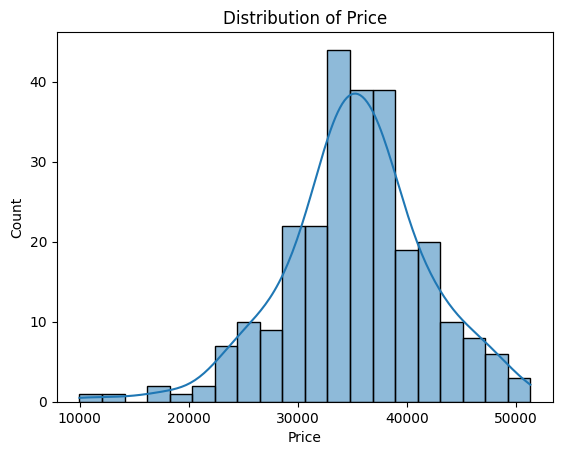

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(grand_cherokee_df['Price'], kde=True)
plt.title("Distribution of Price")
plt.show()

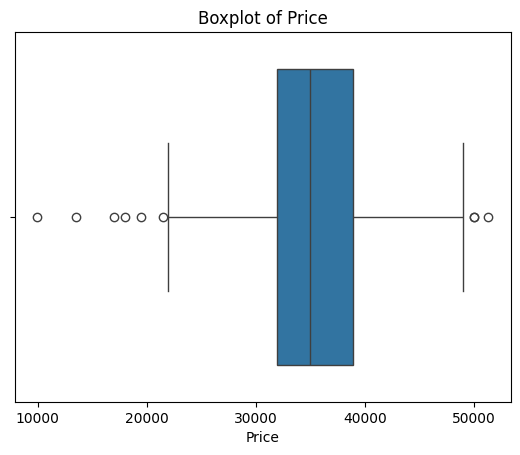

In [ ]:
# Boxplot for Price
sns.boxplot(x=grand_cherokee_df['Price'])
plt.title("Boxplot of Price")
plt.show()

In [16]:
# We can see the Price below 20k is an outlier, as is the price above 50k. We'll drop these outliers for a new df. However, these points might represent some relationships, such as old cars or cars with high mileage, so we'll retain our old dataset.
grand_cherokee_df_without_price_outliers = grand_cherokee_df[(grand_cherokee_df['Price'] >= 20000) & (grand_cherokee_df['Price'] <= 50000)]

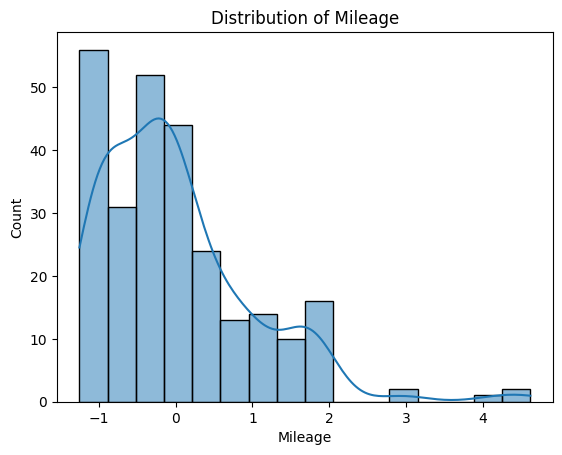

In [18]:
sns.histplot(grand_cherokee_df['Mileage'], kde=True)
plt.title("Distribution of Mileage")
plt.show()

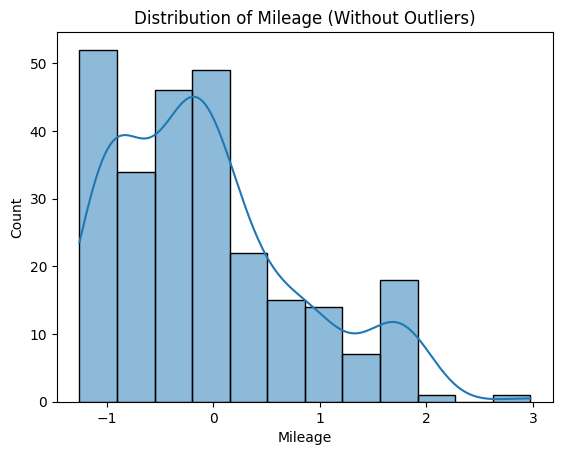

In [19]:
sns.histplot(grand_cherokee_df_without_price_outliers['Mileage'], kde=True)
plt.title("Distribution of Mileage (Without Outliers)")
plt.show()


In [ ]:
print("We can see that when we remove the outliers, the distribution of Mileage is more normal, with a slight right skew. This is expected, as most cars will have mileage in the 20k-100k range, with some outliers for high mileage cars.")

Conclusions:

Manual research verified the authenticity of data. By comparing VINs on Carfax with the VINs from the dataset, we verified the make/model/year of various cars.

Some of the dealers with low ratings, such as CarLotz Denver and EchoPark Automotive Salt Lake City Delivery Center, were permanently closed. 